CELL 1: Imports and Setup

In [ ]:
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import random
import pickle
import warnings

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from dataset_cifar import get_federated_dataloaders
from models_cifar import get_resnet18_classifier
from utils_cifar import calculate_entropy, compute_dynamic_mu, evaluate_resnet26
from client_cifar import train_client_resnet_dp, train_client_resnet_nodp
from server_cifar import federated_averaging

In [8]:
warnings.filterwarnings('ignore')

In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"CUDA Available: {torch.cuda.is_available()}")
print(f"Device Name: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")
print(f"PyTorch Version: {torch.__version__}")

CUDA Available: True
Device Name: NVIDIA GeForce RTX 3050 Laptop GPU
PyTorch Version: 2.6.0+cu124


In [10]:
def set_seed(seed=42):
    """Locks all random number generators for exact reproducibility."""
    np.random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

In [11]:
set_seed(42)

CELL 2: Data Loading & Hybrid Weight Calculation (alpha = 0.1)

In [12]:
num_clients = 5
num_classes = 10

client_loaders, test_loader = get_federated_dataloaders(num_clients=num_clients, alpha=0.1, batch_size=64)

class_names = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

entropies = []
org_distributions = []
sample_counts = [] 

for i, loader in enumerate(client_loaders):
    # Extract labels directly from the underlying Subset indices for speed
    subset = loader.dataset
    labels = np.array(subset.dataset.targets)[subset.indices]
    entropies.append(calculate_entropy(labels, num_classes=num_classes))
    
    counts = np.bincount(labels, minlength=num_classes)
    org_distributions.append(counts)
    sample_counts.append(len(labels)) 

# Lower lambda_scale at 0.5 to prevent paralyzing skewed organizations
dynamic_mus = compute_dynamic_mu(entropies, num_classes=num_classes, mu_base=0.01, lambda_scale=0.5)

# Pure Exponential Entropy Weighting
fedshield_weights = [np.exp(e) for e in entropies]

# Sub-linear (Square-Root) Volume + Exponential Entropy Weighting
fedshield_weights_v2 = [np.sqrt(n) * np.exp(e) for e, n in zip(entropies, sample_counts)]

# Display Formatted Matrix
df_dist = pd.DataFrame(org_distributions, columns=[f"{c} (C{idx})" for idx, c in enumerate(class_names)])
df_dist.insert(0, "Organization", [f"Org {i+1}" for i in range(num_clients)])
df_dist["Total Samples"] = sample_counts
df_dist["Entropy (H_k)"] = [f"{h:.4f}" for h in entropies]
df_dist["Assigned mu_k"] = [f"{m:.4f}" for m in dynamic_mus]
df_dist["Exp Weight"] = [f"{w:.2f}" for w in fedshield_weights] 

print("\n========================= ORGANIZATION CLASS DISTRIBUTION MATRIX =========================")
print(df_dist.to_string(index=False))
print("==========================================================================================\n")

print("--- FedShieldFull2 Hybrid Weights ---")
for i in range(num_clients):
    print(f"Org {i+1} | sqrt(n) * exp(H): {fedshield_weights_v2[i]:.4f}")

Downloading/Loading CIFAR-10 dataset with Augmentation...


100%|██████████| 170M/170M [55:53<00:00, 50.8kB/s]   


Data Partitioning Complete across 5 Organizations.

========================= ORGANIZATION CLASS DISTRIBUTION MATRIX =========================
Organization  airplane (C0)  automobile (C1)  bird (C2)  cat (C3)  deer (C4)  dog (C5)  frog (C6)  horse (C7)  ship (C8)  truck (C9)  Total Samples Entropy (H_k) Assigned mu_k Exp Weight
       Org 1              0                0       4543         5        149      4902       3265           0          0           0          12864        1.6417        0.0184       5.16
       Org 2             24                3        118         0       4767        67        117        4710       4514           0          14320        1.7489        0.0179       5.75
       Org 3              0             4435          2         0          0         0         44         160        332           9           4982        0.6503        0.0234       1.92
       Org 4           1496              561        313      4660         83         9       1573         129

CELL 3: DP Training Function

In [13]:
def run_resnet_experiment(algorithm_name="FedShield", num_rounds=15):
    print(f"\n========== STARTING DP PHASE: {algorithm_name} ==========")
    
    global_model = get_resnet18_classifier(num_classes=10, freeze_backbone=True).to(device)
    auc_history = []
    final_eps = 0.0
    final_targets, final_preds = [], []

    for round_num in range(num_rounds):
        client_models = []
        is_final_round = (round_num == num_rounds - 1)
        
        for i in range(num_clients):
            local_model = copy.deepcopy(global_model)
            
            if algorithm_name == "FedAvg":
                current_mu = 0.0
            elif algorithm_name == "FedProx":
                current_mu = 0.01
            else:
                current_mu = dynamic_mus[i]
                
            trained_model, eps = train_client_resnet_dp(
                local_model=local_model, global_model=global_model,
                train_loader=client_loaders[i], mu=current_mu,
                device=device, epochs=2, lr=0.1, 
                noise_multiplier=1.2, max_grad_norm=1.0
            )
            client_models.append(trained_model)
            final_eps = eps

        # Server Aggregation Logic
        if algorithm_name == "FedShield":
            global_model = federated_averaging(global_model, client_models, weights=fedshield_weights)
        elif algorithm_name == "FedShieldFull2":
            global_model = federated_averaging(global_model, client_models, weights=fedshield_weights_v2)
        else: # FedAvg, FedProx, FedShield_Local all route here for n_k / N
            global_model = federated_averaging(global_model, client_models, weights=sample_counts) 
        
        # Grab predictions only on the final round
        if is_final_round:
            acc, auc, all_targets, all_preds = evaluate_resnet(global_model, test_loader, device, return_preds=True)
            final_targets, final_preds = all_targets, all_preds
        else:
            acc, auc = evaluate_resnet(global_model, test_loader, device, return_preds=False)
            
        auc_history.append(auc)
        print(f"Round {round_num + 1:02d}/{num_rounds:02d} | Global Test AUC: {auc:.4f} | Accuracy: {acc:.4f}")

    print(f"\nFinal {algorithm_name} AUC: {auc_history[-1]:.4f} | Epsilon: {final_eps:.2f}")
    
    # Print full 10-class report and plot the 10x10 matrix
    print(f"\n--- {algorithm_name} (DP) Classification Report ---")
    print(classification_report(final_targets, final_preds, target_names=class_names, digits=4, zero_division=0))
    
    cm = confusion_matrix(final_targets, final_preds)
    fig, ax = plt.subplots(figsize=(9, 9))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(cmap=plt.cm.Blues, values_format='d', ax=ax)
    plt.title(f"{algorithm_name} DP Confusion Matrix (CIFAR-10)")
    plt.xticks(rotation=45) 
    plt.tight_layout()
    plt.show()
    
    return auc_history, global_model

Cell 4: Run DP Experiments & Plot


========== STARTING DP PHASE: FedAvg ==========
Round 01/15 | Global Test AUC: 0.7642 | Accuracy: 0.2549
Round 02/15 | Global Test AUC: 0.8090 | Accuracy: 0.3642
Round 03/15 | Global Test AUC: 0.8257 | Accuracy: 0.3861
Round 04/15 | Global Test AUC: 0.8380 | Accuracy: 0.3961
Round 05/15 | Global Test AUC: 0.8571 | Accuracy: 0.4299
Round 06/15 | Global Test AUC: 0.8700 | Accuracy: 0.4597
Round 07/15 | Global Test AUC: 0.8691 | Accuracy: 0.4559
Round 08/15 | Global Test AUC: 0.8783 | Accuracy: 0.4957
Round 09/15 | Global Test AUC: 0.8745 | Accuracy: 0.4797
Round 10/15 | Global Test AUC: 0.8819 | Accuracy: 0.4852
Round 11/15 | Global Test AUC: 0.8795 | Accuracy: 0.4826
Round 12/15 | Global Test AUC: 0.8870 | Accuracy: 0.5079
Round 13/15 | Global Test AUC: 0.8844 | Accuracy: 0.4937
Round 14/15 | Global Test AUC: 0.8873 | Accuracy: 0.4919
Round 15/15 | Global Test AUC: 0.8921 | Accuracy: 0.5038

Final FedAvg AUC: 0.8921 | Epsilon: 0.82

--- FedAvg (DP) Classification Report ---
           

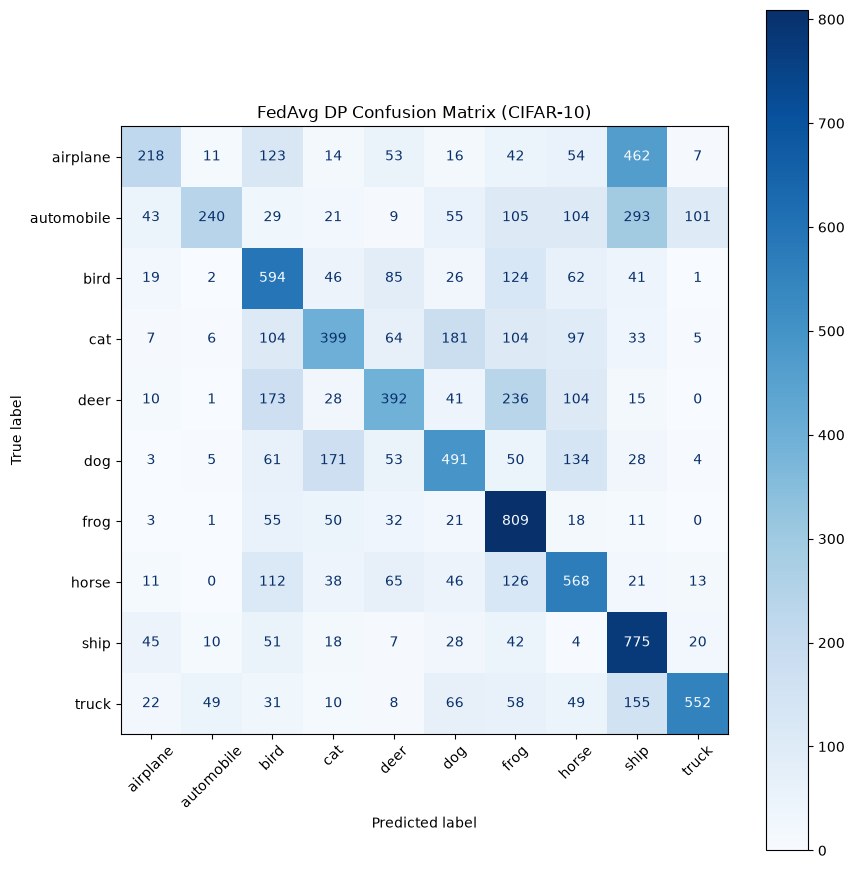

In [14]:
auc_fedavg, _ = run_resnet_experiment("FedAvg", num_rounds=15)



========== STARTING DP PHASE: FedProx ==========
Round 01/15 | Global Test AUC: 0.7723 | Accuracy: 0.2704
Round 02/15 | Global Test AUC: 0.8257 | Accuracy: 0.3479
Round 03/15 | Global Test AUC: 0.8475 | Accuracy: 0.4365
Round 04/15 | Global Test AUC: 0.8687 | Accuracy: 0.4829
Round 05/15 | Global Test AUC: 0.8631 | Accuracy: 0.4523
Round 06/15 | Global Test AUC: 0.8764 | Accuracy: 0.4910
Round 07/15 | Global Test AUC: 0.8777 | Accuracy: 0.4820
Round 08/15 | Global Test AUC: 0.8782 | Accuracy: 0.4881
Round 09/15 | Global Test AUC: 0.8759 | Accuracy: 0.4792
Round 10/15 | Global Test AUC: 0.8827 | Accuracy: 0.4920
Round 11/15 | Global Test AUC: 0.8786 | Accuracy: 0.4922
Round 12/15 | Global Test AUC: 0.8873 | Accuracy: 0.5079
Round 13/15 | Global Test AUC: 0.8856 | Accuracy: 0.5007
Round 14/15 | Global Test AUC: 0.8920 | Accuracy: 0.5195
Round 15/15 | Global Test AUC: 0.8869 | Accuracy: 0.5059

Final FedProx AUC: 0.8869 | Epsilon: 0.82

--- FedProx (DP) Classification Report ---
        

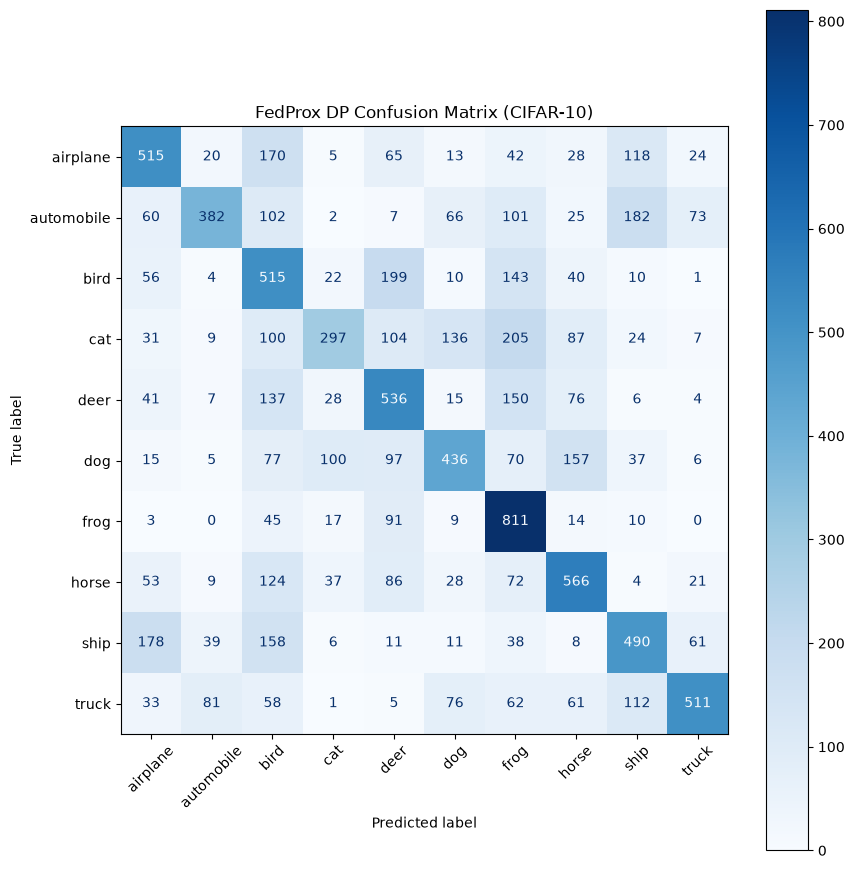

In [15]:
auc_fedprox, _ = run_resnet_experiment("FedProx", num_rounds=15)



========== STARTING DP PHASE: FedShield ==========
Round 01/15 | Global Test AUC: 0.7507 | Accuracy: 0.2404
Round 02/15 | Global Test AUC: 0.8293 | Accuracy: 0.3817
Round 03/15 | Global Test AUC: 0.8595 | Accuracy: 0.4443
Round 04/15 | Global Test AUC: 0.8572 | Accuracy: 0.4223
Round 05/15 | Global Test AUC: 0.8725 | Accuracy: 0.4714
Round 06/15 | Global Test AUC: 0.8802 | Accuracy: 0.4816
Round 07/15 | Global Test AUC: 0.8934 | Accuracy: 0.5204
Round 08/15 | Global Test AUC: 0.8954 | Accuracy: 0.5298
Round 09/15 | Global Test AUC: 0.8922 | Accuracy: 0.5153
Round 10/15 | Global Test AUC: 0.8977 | Accuracy: 0.5327
Round 11/15 | Global Test AUC: 0.8985 | Accuracy: 0.5280
Round 12/15 | Global Test AUC: 0.9017 | Accuracy: 0.5402
Round 13/15 | Global Test AUC: 0.9007 | Accuracy: 0.5373
Round 14/15 | Global Test AUC: 0.8997 | Accuracy: 0.5499
Round 15/15 | Global Test AUC: 0.9027 | Accuracy: 0.5511

Final FedShield AUC: 0.9027 | Epsilon: 0.82

--- FedShield (DP) Classification Report ---
  

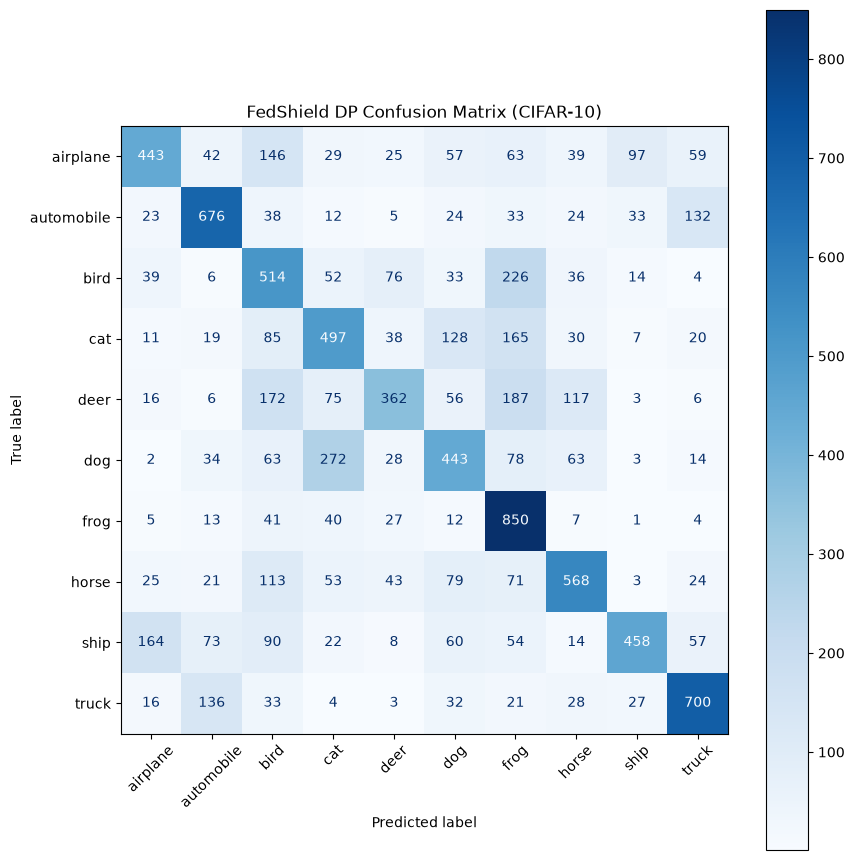

In [16]:

auc_fedshield, final_model_1 = run_resnet_experiment("FedShield", num_rounds=15)



========== STARTING DP PHASE: FedShieldFull2 ==========
Round 01/15 | Global Test AUC: 0.7956 | Accuracy: 0.3227
Round 02/15 | Global Test AUC: 0.8304 | Accuracy: 0.3816
Round 03/15 | Global Test AUC: 0.8522 | Accuracy: 0.4387
Round 04/15 | Global Test AUC: 0.8631 | Accuracy: 0.4524
Round 05/15 | Global Test AUC: 0.8724 | Accuracy: 0.4690
Round 06/15 | Global Test AUC: 0.8785 | Accuracy: 0.4769
Round 07/15 | Global Test AUC: 0.8866 | Accuracy: 0.5181
Round 08/15 | Global Test AUC: 0.8827 | Accuracy: 0.4984
Round 09/15 | Global Test AUC: 0.8844 | Accuracy: 0.5064
Round 10/15 | Global Test AUC: 0.8858 | Accuracy: 0.5136
Round 11/15 | Global Test AUC: 0.8883 | Accuracy: 0.5157
Round 12/15 | Global Test AUC: 0.8865 | Accuracy: 0.5131
Round 13/15 | Global Test AUC: 0.8868 | Accuracy: 0.5073
Round 14/15 | Global Test AUC: 0.8884 | Accuracy: 0.5102
Round 15/15 | Global Test AUC: 0.8955 | Accuracy: 0.5348

Final FedShieldFull2 AUC: 0.8955 | Epsilon: 0.82

--- FedShieldFull2 (DP) Classificatio

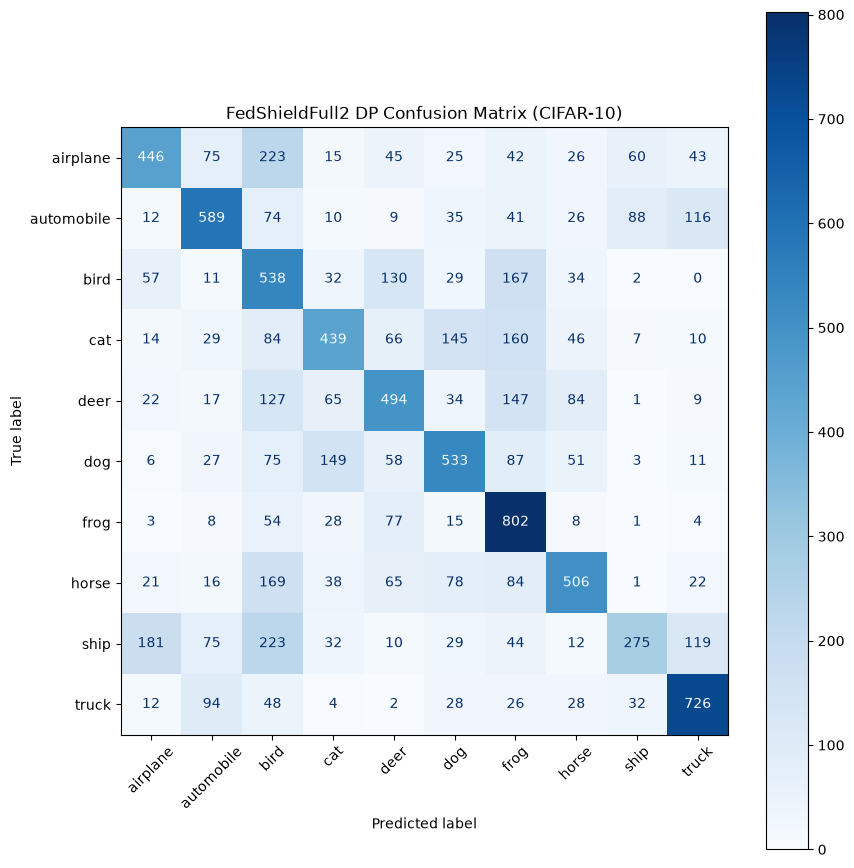

In [17]:

auc_fedshield2, final_model_2 = run_resnet_experiment("FedShieldFull2", num_rounds=15)

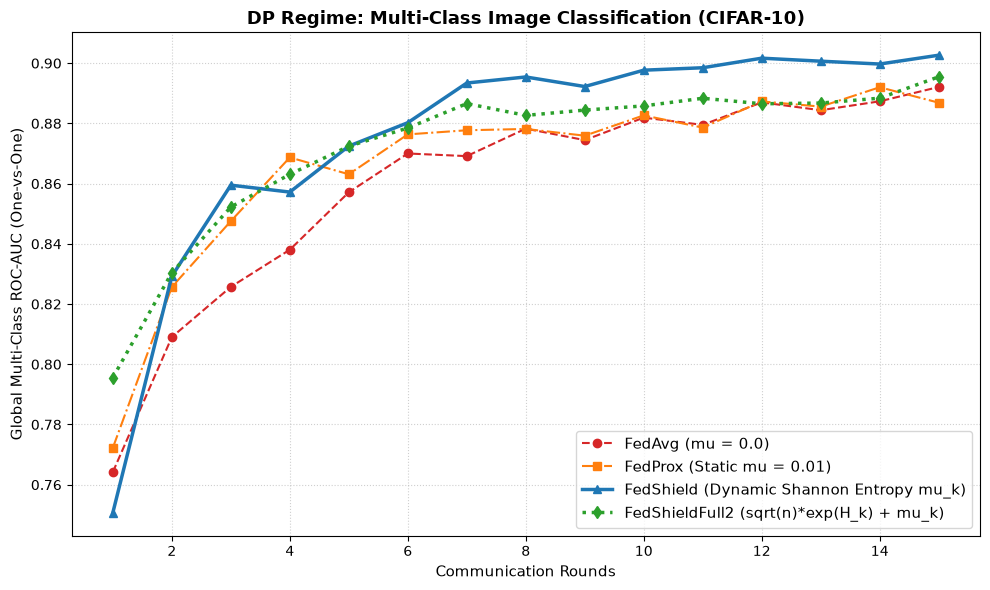

In [18]:
plt.figure(figsize=(10, 6))
rounds_range = range(1, 16)

plt.plot(rounds_range, auc_fedavg, marker='o', linestyle='--', color='tab:red', label='FedAvg (mu = 0.0)')
plt.plot(rounds_range, auc_fedprox, marker='s', linestyle='-.', color='tab:orange', label='FedProx (Static mu = 0.01)')
plt.plot(rounds_range, auc_fedshield, marker='^', linestyle='-', color='tab:blue', linewidth=2.5, label='FedShield (Dynamic Shannon Entropy mu_k)')
plt.plot(rounds_range, auc_fedshield2, marker='d', linestyle=':', color='tab:green', linewidth=2.5, label='FedShieldFull2 (sqrt(n)*exp(H_k) + mu_k)')

plt.title("DP Regime: Multi-Class Image Classification (CIFAR-10)", fontsize=13, fontweight='bold')
plt.xlabel("Communication Rounds", fontsize=11)
plt.ylabel("Global Multi-Class ROC-AUC (One-vs-One)", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

In [19]:
torch.save(final_model_1.state_dict(), "fedshield_resnet18_cifar10_augmented_v1.pth")
torch.save(final_model_2.state_dict(), "2_fedshield_resnet18_cifar10_augmented_v1.pth")

Cell 5: Non-DP Training Function (Ablation Study)

In [20]:
def run_resnet_experiment_nodp(algorithm_name="FedShield", num_rounds=15):
    print(f"\n========== STARTING NON-DP PHASE: {algorithm_name} ==========")
    
    global_model = get_resnet18_classifier(num_classes=10, freeze_backbone=True).to(device)
    auc_history = []
    final_targets, final_preds = [], []

    for round_num in range(num_rounds):
        client_models = []
        is_final_round = (round_num == num_rounds - 1)
        
        for i in range(num_clients):
            local_model = copy.deepcopy(global_model)
            
            if algorithm_name == "FedAvg":
                current_mu = 0.0
            elif algorithm_name == "FedProx":
                current_mu = 0.01
            else:
                current_mu = dynamic_mus[i]
                
            trained_model, _ = train_client_resnet_nodp(
                local_model=local_model, global_model=global_model,
                train_loader=client_loaders[i], mu=current_mu,
                device=device, epochs=2, lr=0.1
            )
            client_models.append(trained_model)

        # Server Aggregation Logic
        if algorithm_name == "FedShield_Full":
            global_model = federated_averaging(global_model, client_models, weights=fedshield_weights)
        elif algorithm_name == "FedShieldFull2":
            global_model = federated_averaging(global_model, client_models, weights=fedshield_weights_v2)
        else: # FedAvg, FedProx, FedShield_Local all route here for n_k / N
            global_model = federated_averaging(global_model, client_models, weights=sample_counts)
        
        if is_final_round:
            acc, auc, all_targets, all_preds = evaluate_resnet(global_model, test_loader, device, return_preds=True)
            final_targets, final_preds = all_targets, all_preds
        else:
            acc, auc = evaluate_resnet(global_model, test_loader, device, return_preds=False)
            
        auc_history.append(auc)
        print(f"Round {round_num + 1:02d}/{num_rounds:02d} | Global Test AUC: {auc:.4f} | Accuracy: {acc:.4f}")

    print(f"\nFinal Non-DP {algorithm_name} AUC: {auc_history[-1]:.4f}")
    
    print(f"\n--- {algorithm_name} (No-DP) Classification Report ---")
    print(classification_report(final_targets, final_preds, target_names=class_names, digits=4, zero_division=0))
    
    cm = confusion_matrix(final_targets, final_preds)
    fig, ax = plt.subplots(figsize=(9, 9))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(cmap=plt.cm.Greens, values_format='d', ax=ax)
    plt.title(f"{algorithm_name} No-DP Confusion Matrix (CIFAR-10)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    
    return auc_history, global_model

CELL 6: Run Non-DP Experiments

Starting Non-DP Ablation Study on CIFAR-10...

========== STARTING NON-DP PHASE: FedAvg ==========
Round 01/15 | Global Test AUC: 0.8703 | Accuracy: 0.2632
Round 02/15 | Global Test AUC: 0.9417 | Accuracy: 0.4604
Round 03/15 | Global Test AUC: 0.8933 | Accuracy: 0.3104
Round 04/15 | Global Test AUC: 0.9332 | Accuracy: 0.4929
Round 05/15 | Global Test AUC: 0.9031 | Accuracy: 0.2982
Round 06/15 | Global Test AUC: 0.9439 | Accuracy: 0.4811
Round 07/15 | Global Test AUC: 0.8976 | Accuracy: 0.3365
Round 08/15 | Global Test AUC: 0.9462 | Accuracy: 0.5158
Round 09/15 | Global Test AUC: 0.9096 | Accuracy: 0.3387
Round 10/15 | Global Test AUC: 0.9441 | Accuracy: 0.4876
Round 11/15 | Global Test AUC: 0.9115 | Accuracy: 0.4155
Round 12/15 | Global Test AUC: 0.9460 | Accuracy: 0.4867
Round 13/15 | Global Test AUC: 0.9265 | Accuracy: 0.4059
Round 14/15 | Global Test AUC: 0.9485 | Accuracy: 0.5369
Round 15/15 | Global Test AUC: 0.9223 | Accuracy: 0.4160

Final Non-DP FedAvg AUC: 0.9223

--- FedAvg (

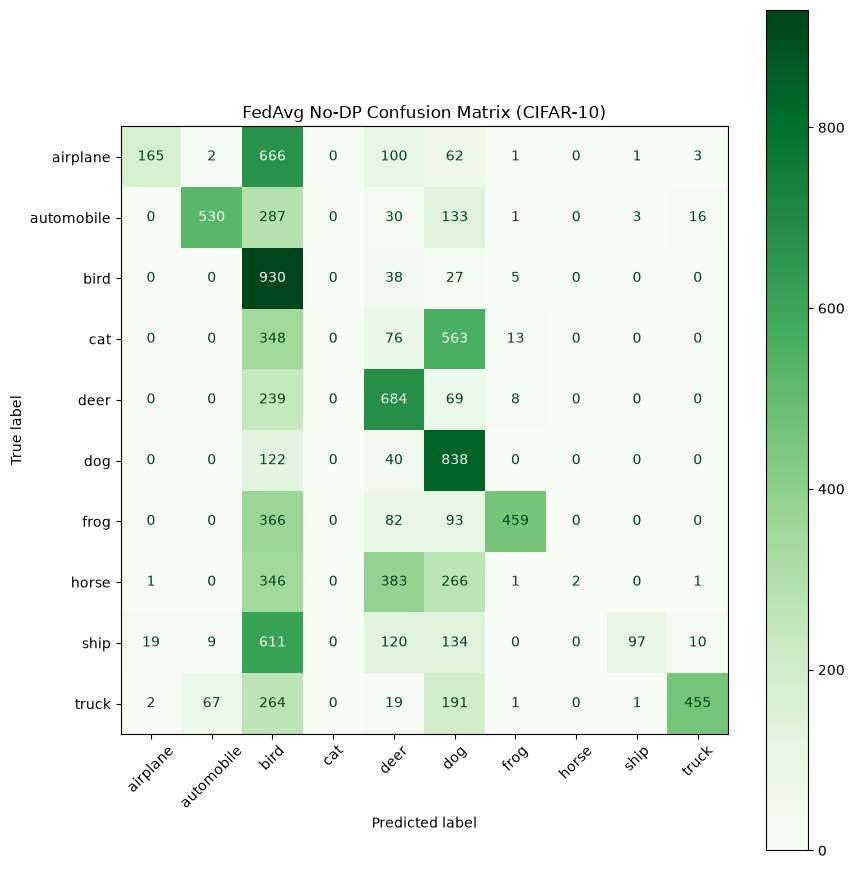

In [21]:
print("Starting Non-DP Ablation Study on CIFAR-10...")
nodp_auc_fedavg, nodp_model_fedavg = run_resnet_experiment_nodp("FedAvg", num_rounds=15)



========== STARTING NON-DP PHASE: FedProx ==========
Round 01/15 | Global Test AUC: 0.9424 | Accuracy: 0.4729
Round 02/15 | Global Test AUC: 0.9636 | Accuracy: 0.6978
Round 03/15 | Global Test AUC: 0.9573 | Accuracy: 0.6093
Round 04/15 | Global Test AUC: 0.9662 | Accuracy: 0.7353
Round 05/15 | Global Test AUC: 0.9593 | Accuracy: 0.6362
Round 06/15 | Global Test AUC: 0.9644 | Accuracy: 0.6960
Round 07/15 | Global Test AUC: 0.9637 | Accuracy: 0.6909
Round 08/15 | Global Test AUC: 0.9648 | Accuracy: 0.7032
Round 09/15 | Global Test AUC: 0.9639 | Accuracy: 0.6846
Round 10/15 | Global Test AUC: 0.9650 | Accuracy: 0.6995
Round 11/15 | Global Test AUC: 0.9652 | Accuracy: 0.6926
Round 12/15 | Global Test AUC: 0.9664 | Accuracy: 0.7083
Round 13/15 | Global Test AUC: 0.9636 | Accuracy: 0.6751
Round 14/15 | Global Test AUC: 0.9656 | Accuracy: 0.6987
Round 15/15 | Global Test AUC: 0.9641 | Accuracy: 0.6803

Final Non-DP FedProx AUC: 0.9641

--- FedProx (No-DP) Classification Report ---
          

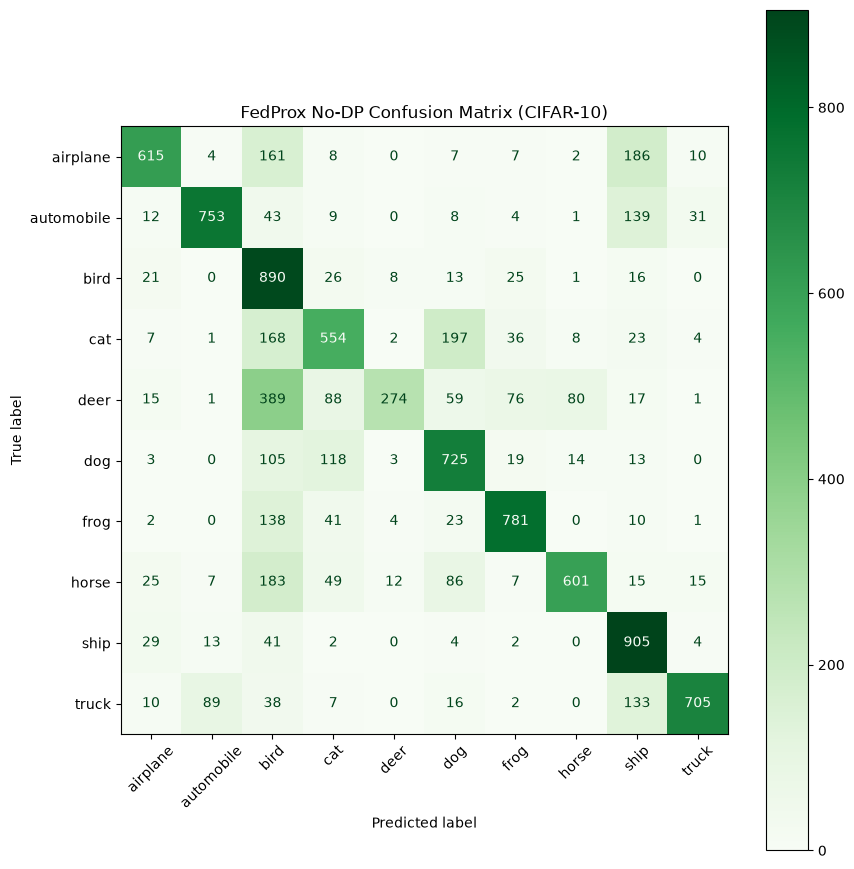

In [22]:
nodp_auc_fedprox, nodp_model_fedprox = run_resnet_experiment_nodp("FedProx", num_rounds=15)



========== STARTING NON-DP PHASE: FedShield_Local ==========
Round 01/15 | Global Test AUC: 0.9341 | Accuracy: 0.4410
Round 02/15 | Global Test AUC: 0.9629 | Accuracy: 0.6988
Round 03/15 | Global Test AUC: 0.9637 | Accuracy: 0.7114
Round 04/15 | Global Test AUC: 0.9649 | Accuracy: 0.7069
Round 05/15 | Global Test AUC: 0.9656 | Accuracy: 0.7269
Round 06/15 | Global Test AUC: 0.9675 | Accuracy: 0.7404
Round 07/15 | Global Test AUC: 0.9669 | Accuracy: 0.7310
Round 08/15 | Global Test AUC: 0.9673 | Accuracy: 0.7394
Round 09/15 | Global Test AUC: 0.9668 | Accuracy: 0.7313
Round 10/15 | Global Test AUC: 0.9680 | Accuracy: 0.7394
Round 11/15 | Global Test AUC: 0.9683 | Accuracy: 0.7426
Round 12/15 | Global Test AUC: 0.9685 | Accuracy: 0.7409
Round 13/15 | Global Test AUC: 0.9687 | Accuracy: 0.7475
Round 14/15 | Global Test AUC: 0.9680 | Accuracy: 0.7342
Round 15/15 | Global Test AUC: 0.9683 | Accuracy: 0.7401

Final Non-DP FedShield_Local AUC: 0.9683

--- FedShield_Local (No-DP) Classificati

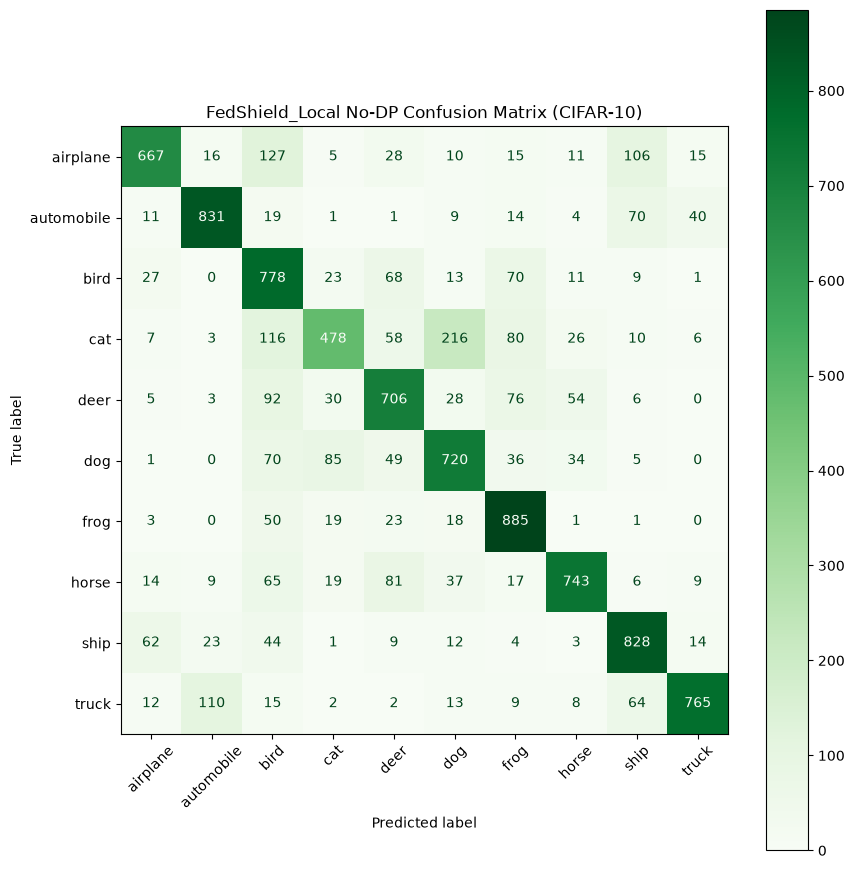

In [23]:
nodp_auc_fedshield_local, nodp_model_fedshield_local = run_resnet_experiment_nodp("FedShield_Local", num_rounds=15)



========== STARTING NON-DP PHASE: FedShield_Full ==========
Round 01/15 | Global Test AUC: 0.9454 | Accuracy: 0.5703
Round 02/15 | Global Test AUC: 0.9620 | Accuracy: 0.7209
Round 03/15 | Global Test AUC: 0.9637 | Accuracy: 0.7260
Round 04/15 | Global Test AUC: 0.9656 | Accuracy: 0.7349
Round 05/15 | Global Test AUC: 0.9663 | Accuracy: 0.7403
Round 06/15 | Global Test AUC: 0.9672 | Accuracy: 0.7448
Round 07/15 | Global Test AUC: 0.9677 | Accuracy: 0.7504
Round 08/15 | Global Test AUC: 0.9672 | Accuracy: 0.7397
Round 09/15 | Global Test AUC: 0.9690 | Accuracy: 0.7539
Round 10/15 | Global Test AUC: 0.9688 | Accuracy: 0.7556
Round 11/15 | Global Test AUC: 0.9690 | Accuracy: 0.7527
Round 12/15 | Global Test AUC: 0.9689 | Accuracy: 0.7536
Round 13/15 | Global Test AUC: 0.9686 | Accuracy: 0.7496
Round 14/15 | Global Test AUC: 0.9691 | Accuracy: 0.7530
Round 15/15 | Global Test AUC: 0.9695 | Accuracy: 0.7533

Final Non-DP FedShield_Full AUC: 0.9695

--- FedShield_Full (No-DP) Classification 

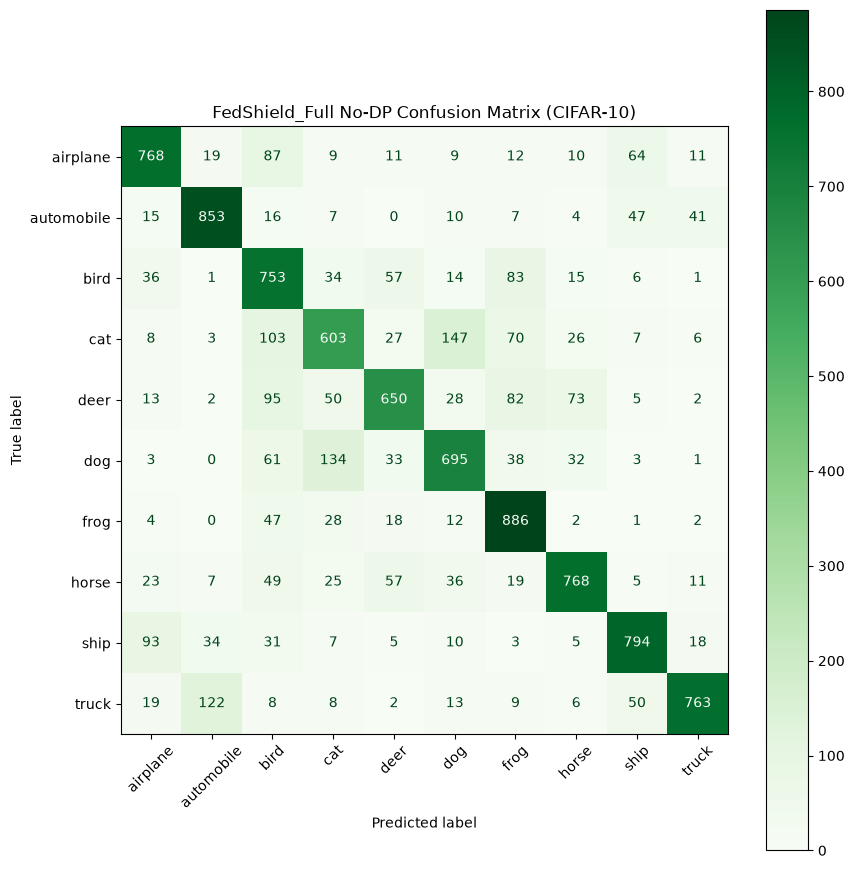

In [24]:
nodp_auc_fedshield_full, nodp_model_fedshield_full = run_resnet_experiment_nodp("FedShield_Full", num_rounds=15)



========== STARTING NON-DP PHASE: FedShieldFull2 ==========
Round 01/15 | Global Test AUC: 0.9455 | Accuracy: 0.6123
Round 02/15 | Global Test AUC: 0.9622 | Accuracy: 0.7282
Round 03/15 | Global Test AUC: 0.9640 | Accuracy: 0.7280
Round 04/15 | Global Test AUC: 0.9657 | Accuracy: 0.7382
Round 05/15 | Global Test AUC: 0.9670 | Accuracy: 0.7430
Round 06/15 | Global Test AUC: 0.9664 | Accuracy: 0.7435
Round 07/15 | Global Test AUC: 0.9680 | Accuracy: 0.7500
Round 08/15 | Global Test AUC: 0.9674 | Accuracy: 0.7417
Round 09/15 | Global Test AUC: 0.9683 | Accuracy: 0.7472
Round 10/15 | Global Test AUC: 0.9679 | Accuracy: 0.7472
Round 11/15 | Global Test AUC: 0.9688 | Accuracy: 0.7496
Round 12/15 | Global Test AUC: 0.9687 | Accuracy: 0.7491
Round 13/15 | Global Test AUC: 0.9690 | Accuracy: 0.7497
Round 14/15 | Global Test AUC: 0.9693 | Accuracy: 0.7535
Round 15/15 | Global Test AUC: 0.9681 | Accuracy: 0.7467

Final Non-DP FedShieldFull2 AUC: 0.9681

--- FedShieldFull2 (No-DP) Classification 

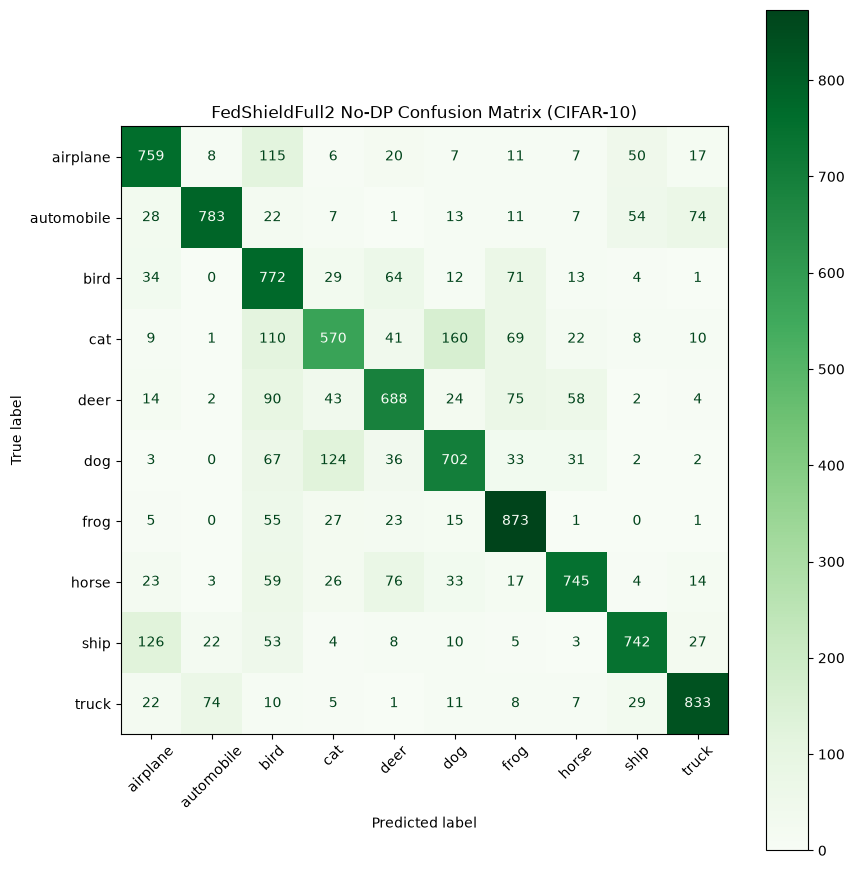

In [25]:
nodp_auc_fedshield_full_2, nodp_model_fedshield_full_2 = run_resnet_experiment_nodp("FedShieldFull2", num_rounds=15)

CELL 7: Plot Non-DP Ablation Study Results & Save Checkpoint

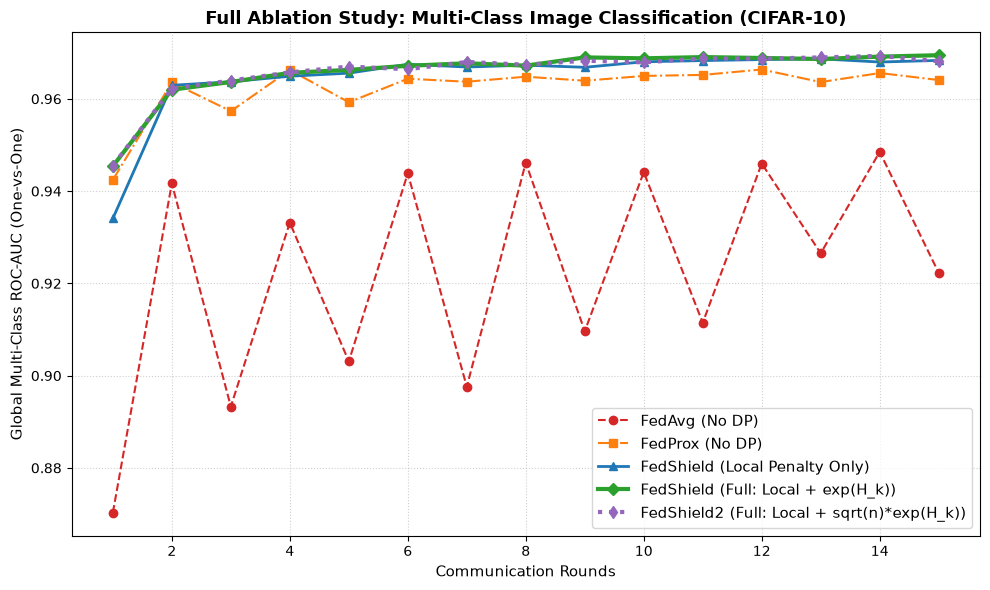

In [26]:
plt.figure(figsize=(10, 6))
rounds_range = range(1, 16)

plt.plot(rounds_range, nodp_auc_fedavg, marker='o', linestyle='--', color='tab:red', label='FedAvg (No DP)')
plt.plot(rounds_range, nodp_auc_fedprox, marker='s', linestyle='-.', color='tab:orange', label='FedProx (No DP)')
plt.plot(rounds_range, nodp_auc_fedshield_local, marker='^', linestyle='-', color='tab:blue', linewidth=2, label='FedShield (Local Penalty Only)')
plt.plot(rounds_range, nodp_auc_fedshield_full, marker='D', linestyle='-', color='tab:green', linewidth=3, label='FedShield (Full: Local + exp(H_k))')
plt.plot(rounds_range, nodp_auc_fedshield_full_2, marker='d', linestyle=':', color='tab:purple', linewidth=3, label='FedShield2 (Full: Local + sqrt(n)*exp(H_k))')

plt.title("Full Ablation Study: Multi-Class Image Classification (CIFAR-10)", fontsize=13, fontweight='bold')
plt.xlabel("Communication Rounds", fontsize=11)
plt.ylabel("Global Multi-Class ROC-AUC (One-vs-One)", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

In [27]:
# Bundle EVERYTHING (DP and Non-DP histories) into one master dictionary
full_context = {
    "auc_fedshield": auc_fedshield,
    "auc_fedshield2": auc_fedshield2,
    "auc_fedprox": auc_fedprox,
    "auc_fedavg": auc_fedavg,
    "entropies": entropies,
    "dynamic_mus": dynamic_mus,
    "fedshield_weights": fedshield_weights,
    "fedshield_weights_v2": fedshield_weights_v2,
    "org_distributions": org_distributions,
    "sample_counts": sample_counts,
    "nodp_auc_fedavg": nodp_auc_fedavg,
    "nodp_auc_fedprox": nodp_auc_fedprox,
    "nodp_auc_fedshield_local": nodp_auc_fedshield_local,
    "nodp_auc_fedshield_full": nodp_auc_fedshield_full,
    "nodp_auc_fedshield_full_2": nodp_auc_fedshield_full_2
}

with open("full_cifar10_experiment_checkpoint_v1.pkl", "wb") as f:
    pickle.dump(full_context, f)

torch.save(final_model_2.state_dict(), "fedshield_dp_cifar10_model_v1.pth")
torch.save(nodp_model_fedavg.state_dict(), "nodp_fedavg_cifar10_model_v1.pth")
torch.save(nodp_model_fedprox.state_dict(), "nodp_fedprox_cifar10_model_v1.pth")
torch.save(nodp_model_fedshield_local.state_dict(), "nodp_fedshield_local_cifar10_model_v1.pth")
torch.save(nodp_model_fedshield_full.state_dict(), "nodp_fedshield_full_cifar10_model_v1.pth")
torch.save(nodp_model_fedshield_full_2.state_dict(), "nodp_fedshield_full_2_cifar10_model_v1.pth")

print("✅ ENTIRE CIFAR-10 kernel state and all models successfully saved!")

✅ ENTIRE CIFAR-10 kernel state and all models successfully saved!
